#Load Libraries

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import classification_report,confusion_matrix, ConfusionMatrixDisplay,roc_auc_score,accuracy_score,roc_curve,precision_score,recall_score,f1_score


#Load Dataset

In [2]:
df = pd.read_csv('/content/drive/MyDrive/ict_aiml/datasets/diabetes_prediction_dataset.csv')

In [3]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
df.shape

(100000, 9)

In [5]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [6]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


#check for missing values

In [7]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


#Check for duplicated values

In [8]:
df.duplicated().sum()

np.int64(3854)

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

#Train Test Split

In [11]:
#Seperate X and y
X = df.drop(columns=['diabetes'],axis = 1)
y = df['diabetes']

# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (76916, 8) Test shape: (19230, 8)


#Check target distribution

In [12]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


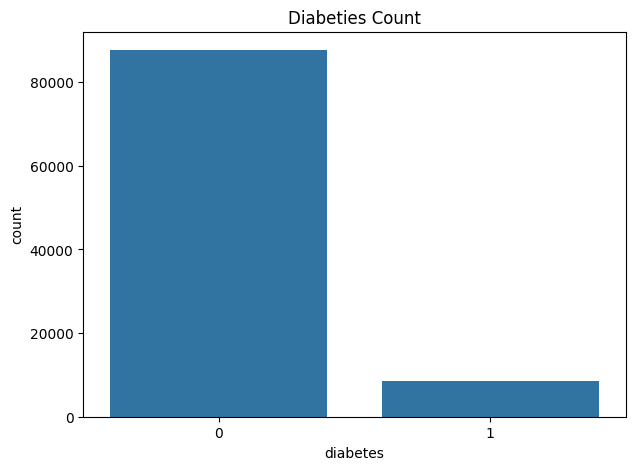

In [13]:
plt.figure(figsize=(7,5))
sns.countplot(data=df,x='diabetes')
plt.title('Diabeties Count')
plt.show()

#Identify numerical and categorical columns

In [14]:
X_train_numerical_columns = X_train.select_dtypes(include = "number")
X_train_numerical_columns.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
79000,45.0,0,0,23.87,5.7,126
32011,64.0,0,0,33.03,4.0,126
95559,45.0,0,0,27.32,6.6,126
32057,44.0,1,0,28.86,4.8,80
97797,27.0,0,0,26.48,6.5,200


In [15]:
X_train_categorical_columns = X_train.select_dtypes(include='object')
X_train_categorical_columns.head()

,gender,smoking_history
79000,Male,No Info
32011,Female,former
95559,Female,No Info
32057,Male,No Info
97797,Female,not current


In [16]:
X_test_numerical_columns = X_test.select_dtypes(include= "number")
X_test_numerical_columns.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
82004,51.0,0,0,36.77,6.6,159
10542,12.0,0,0,22.29,4.5,90
31572,60.0,1,0,34.24,6.2,90
98055,80.0,0,0,24.39,4.0,100
49107,80.0,0,1,35.00,4.5,145


In [17]:
X_test_categorical_columns = X_test.select_dtypes(include="object")
X_test_categorical_columns.head()

,gender,smoking_history
82004,Female,current
10542,Male,No Info
31572,Female,former
98055,Male,former
49107,Male,No Info


#Encoding

In [18]:
X_test_categorical_columns.columns

Index(['gender', 'smoking_history'], dtype='object')

In [19]:
X_train_categorical_columns.columns

Index(['gender', 'smoking_history'], dtype='object')

In [20]:
for col in X_train_categorical_columns.columns:
    print(f"\n{col}:")
    print(X_train_categorical_columns[col].unique())


gender:
['Male' 'Female' 'Other']

smoking_history:
['No Info' 'former' 'not current' 'never' 'current' 'ever']


In [21]:
categorical_cols = ['gender', 'smoking_history']

In [22]:
#one hot encoding
ohe = OneHotEncoder(
    drop='first',
    handle_unknown='ignore',
    sparse_output=False
)
X_train_ohe = ohe.fit_transform(X_train[categorical_cols])
X_test_ohe = ohe.transform(X_test[categorical_cols])
ohe.get_feature_names_out(categorical_cols)

array(['gender_Male', 'gender_Other', 'smoking_history_current',
       'smoking_history_ever', 'smoking_history_former',
       'smoking_history_never', 'smoking_history_not current'],
      dtype=object)

In [23]:
X_train_ohe = pd.DataFrame(
    X_train_ohe,
    columns=ohe.get_feature_names_out(categorical_cols),
    index=X_train.index
)

X_test_ohe = pd.DataFrame(
    X_test_ohe,
    columns=ohe.get_feature_names_out(categorical_cols),
    index=X_test.index
)

In [24]:
X_train_ohe.head()


,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
79000,1.0,0.0,0.0,0.0,0.0,0.0,0.0
32011,0.0,0.0,0.0,0.0,1.0,0.0,0.0
95559,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32057,1.0,0.0,0.0,0.0,0.0,0.0,0.0
97797,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [25]:
X_test_ohe.head()

,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
82004,0.0,0.0,1.0,0.0,0.0,0.0,0.0
10542,1.0,0.0,0.0,0.0,0.0,0.0,0.0
31572,0.0,0.0,0.0,0.0,1.0,0.0,0.0
98055,1.0,0.0,0.0,0.0,1.0,0.0,0.0
49107,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
# Concatenate numerical + One-Hot encoded categorical columns
X_train = pd.concat(
    [X_train_numerical_columns, X_train_ohe],
    axis=1
)

X_test = pd.concat(
    [X_test_numerical_columns, X_test_ohe],
    axis=1
)

# Check the result
print("X_train final shape:", X_train.shape)
print("X_test final shape:", X_test.shape)

X_train.head()

X_train final shape: (76916, 13)
X_test final shape: (19230, 13)


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
79000,45.0,0,0,23.87,5.7,126,1.0,0.0,0.0,0.0,0.0,0.0,0.0
32011,64.0,0,0,33.03,4.0,126,0.0,0.0,0.0,0.0,1.0,0.0,0.0
95559,45.0,0,0,27.32,6.6,126,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32057,44.0,1,0,28.86,4.8,80,1.0,0.0,0.0,0.0,0.0,0.0,0.0
97797,27.0,0,0,26.48,6.5,200,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [27]:
X_test.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
82004,51.0,0,0,36.77,6.6,159,0.0,0.0,1.0,0.0,0.0,0.0,0.0
10542,12.0,0,0,22.29,4.5,90,1.0,0.0,0.0,0.0,0.0,0.0,0.0
31572,60.0,1,0,34.24,6.2,90,0.0,0.0,0.0,0.0,1.0,0.0,0.0
98055,80.0,0,0,24.39,4.0,100,1.0,0.0,0.0,0.0,1.0,0.0,0.0
49107,80.0,0,1,35.00,4.5,145,1.0,0.0,0.0,0.0,0.0,0.0,0.0


#correlation matrix

In [28]:
# Create a copy so original X_train is not modified
train_corr = X_train.copy()

# Add target
train_corr['diabetes'] = y_train

In [29]:
corr_matrix = train_corr.corr()

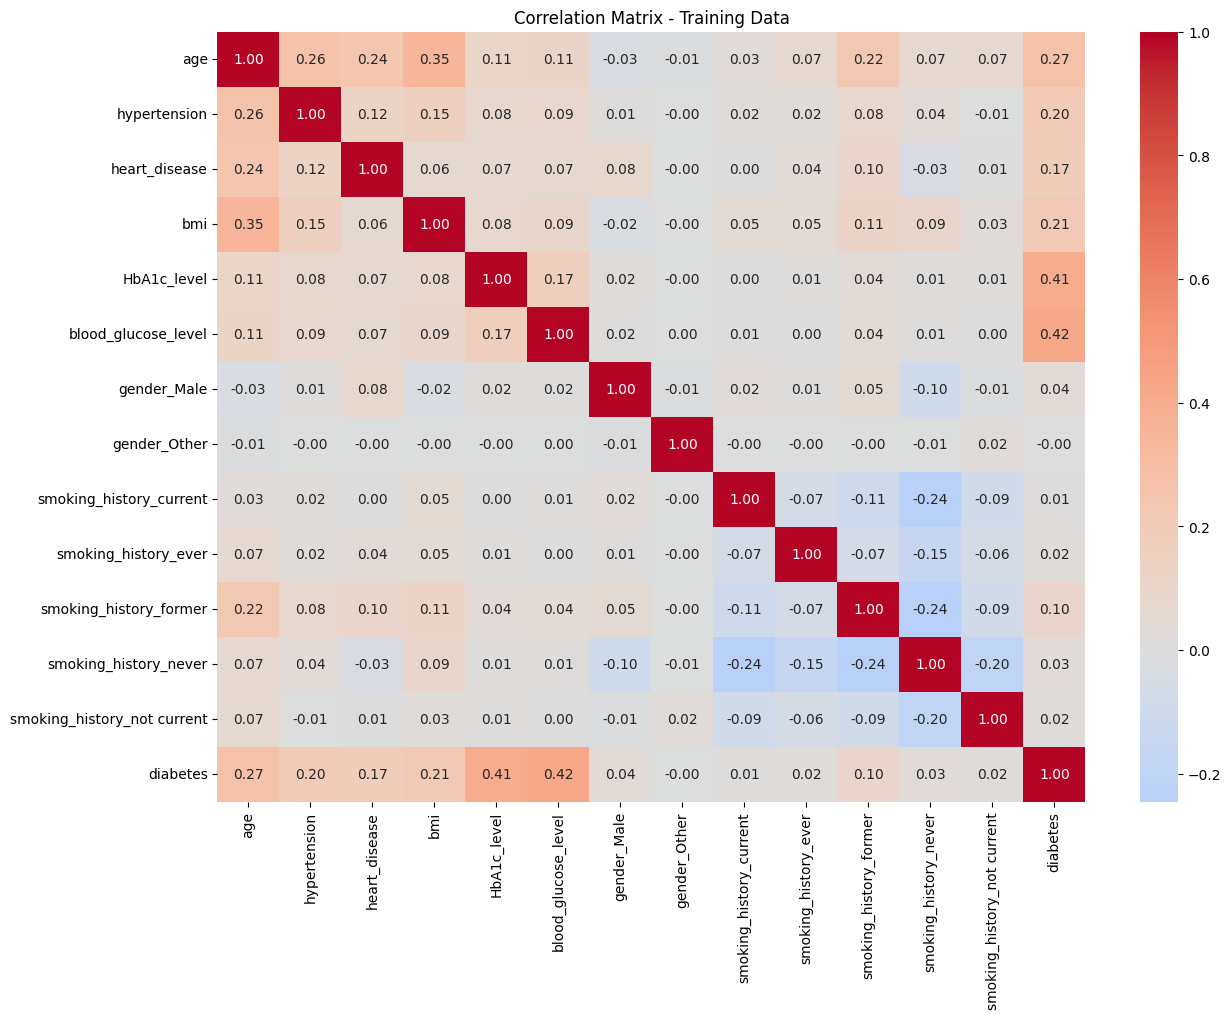

In [30]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix - Training Data')
plt.show()

In [31]:
target_corr = corr_matrix['diabetes'].sort_values(ascending=False)

print(target_corr)

diabetes                       1.000000
blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
Name: diabetes, dtype: float64


In [32]:
print(
    train_corr.corr()['diabetes']
    .loc[lambda x: x.abs() > 0.1]
)

age                    0.266649
hypertension           0.199069
heart_disease          0.174470
bmi                    0.213456
HbA1c_level            0.405321
blood_glucose_level    0.423011
diabetes               1.000000
Name: diabetes, dtype: float64


In [33]:
selected_features = [
    'age',
    'bmi',
    'hypertension',
    'heart_disease',
    #'HbA1c_level',
    'blood_glucose_level',
    'smoking_history_former'
]

In [34]:
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

print("X_train_selected shape:", X_train_selected.shape)
print("X_test_selected shape:", X_test_selected.shape)

X_train_selected.head()

X_train_selected shape: (76916, 6)
X_test_selected shape: (19230, 6)


,age,bmi,hypertension,heart_disease,blood_glucose_level,smoking_history_former
79000,45.0,23.87,0,0,126,0.0
32011,64.0,33.03,0,0,126,1.0
95559,45.0,27.32,0,0,126,0.0
32057,44.0,28.86,1,0,80,0.0
97797,27.0,26.48,0,0,200,0.0


#Scaling

In [35]:
# Continuous numerical features
continuous_cols = [
    'age',
    'bmi',
    #'HbA1c_level',
    'blood_glucose_level'
]

# Create copies
X_train_scaled = X_train_selected.copy()
X_test_scaled = X_test_selected.copy()

# Create scaler
scaler = StandardScaler()

# Fit ONLY on training data and transform training data
X_train_scaled[continuous_cols] = scaler.fit_transform(
    X_train_selected[continuous_cols]
)

# Transform test data using the same fitted scaler
X_test_scaled[continuous_cols] = scaler.transform(
    X_test_selected[continuous_cols]
)

# Check
print("Training data:")
display(X_train_scaled.head())

print("\nTest data:")
display(X_test_scaled.head())

Training data:


,age,bmi,hypertension,heart_disease,blood_glucose_level,smoking_history_former
79000,0.144164,-0.509643,0,0,-0.296217,0.0
32011,0.989825,0.845956,0,0,-0.296217,1.0
95559,0.144164,0.000927,0,0,-0.296217,0.0
32057,0.099655,0.228833,1,0,-1.421004,0.0
97797,-0.656989,-0.123386,0,0,1.513222,0.0



Test data:


,age,bmi,hypertension,heart_disease,blood_glucose_level,smoking_history_former
82004,0.411215,1.399442,0,0,0.510695,0.0
10542,-1.324617,-0.743469,0,0,-1.176485,0.0
31572,0.811791,1.025025,1,0,-1.176485,1.0
98055,1.701962,-0.432687,0,0,-0.931966,1.0
49107,1.701962,1.137498,0,1,0.168369,0.0


#Class Imbalane

In [36]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTraining class percentage:")
print(y_train.value_counts(normalize=True) * 100)

Training class distribution:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Training class percentage:
diabetes
0    91.177388
1     8.822612
Name: proportion, dtype: float64


In [37]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

After SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


In [38]:
X_train_smote.head()

,age,bmi,hypertension,heart_disease,blood_glucose_level,smoking_history_former
0,0.144164,-0.509643,0,0,-0.296217,0.0
1,0.989825,0.845956,0,0,-0.296217,1.0
2,0.144164,0.000927,0,0,-0.296217,0.0
3,0.099655,0.228833,1,0,-1.421004,0.0
4,-0.656989,-0.123386,0,0,1.513222,0.0


#Models

In [39]:
lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)

rf = RandomForestClassifier(
    random_state=42,
    n_estimators=100
)

xgb = XGBClassifier(
    random_state=42,
    n_estimators=100,
    eval_metric='logloss'
)

#Fit model

In [40]:
# Logistic Regression
lr.fit(X_train_smote, y_train_smote)

# Random Forest
rf.fit(X_train_smote, y_train_smote)

# XGBoost
xgb.fit(X_train_smote, y_train_smote)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

#Make predictions

In [41]:
y_pred_lr = lr.predict(X_test_scaled)
y_pred_rf = rf.predict(X_test_scaled)
y_pred_xgb = xgb.predict(X_test_scaled)

In [42]:
print("Logistic Regression predictions:")
print(y_pred_lr[:10])

print("\nRandom Forest predictions:")
print(y_pred_rf[:10])

print("\nXGBoost predictions:")
print(y_pred_xgb[:10])

Logistic Regression predictions:
[1 0 0 0 1 0 0 1 0 0]

Random Forest predictions:
[0 0 0 0 1 0 0 0 0 0]

XGBoost predictions:
[0 0 0 0 1 0 0 1 0 0]


In [43]:
X_test_scaled.head()

,age,bmi,hypertension,heart_disease,blood_glucose_level,smoking_history_former
82004,0.411215,1.399442,0,0,0.510695,0.0
10542,-1.324617,-0.743469,0,0,-1.176485,0.0
31572,0.811791,1.025025,1,0,-1.176485,1.0
98055,1.701962,-0.432687,0,0,-0.931966,1.0
49107,1.701962,1.137498,0,1,0.168369,0.0


In [44]:
y_test.head(10)

,diabetes
82004,0
10542,0
31572,0
98055,0
49107,0
14248,0
28877,0
52552,0
10919,0
30225,0


#classification report

In [45]:
print("Logistic Regression")
print(classification_report(y_test, y_pred_lr))

print("Random Forest")
print(classification_report(y_test, y_pred_rf))

print("XGBoost")
print(classification_report(y_test, y_pred_xgb))

Logistic Regression
              precision    recall  f1-score   support

           0       0.98      0.81      0.89     17534
           1       0.29      0.80      0.43      1696

    accuracy                           0.81     19230
   macro avg       0.63      0.81      0.66     19230
weighted avg       0.92      0.81      0.85     19230

Random Forest
              precision    recall  f1-score   support

           0       0.96      0.94      0.95     17534
           1       0.47      0.58      0.52      1696

    accuracy                           0.91     19230
   macro avg       0.71      0.76      0.73     19230
weighted avg       0.92      0.91      0.91     19230

XGBoost
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     17534
           1       0.55      0.55      0.55      1696

    accuracy                           0.92     19230
   macro avg       0.75      0.75      0.75     19230
weighted avg       0.92      0.9

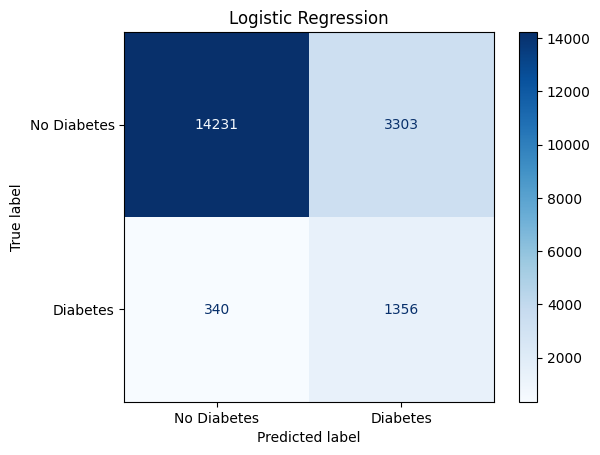

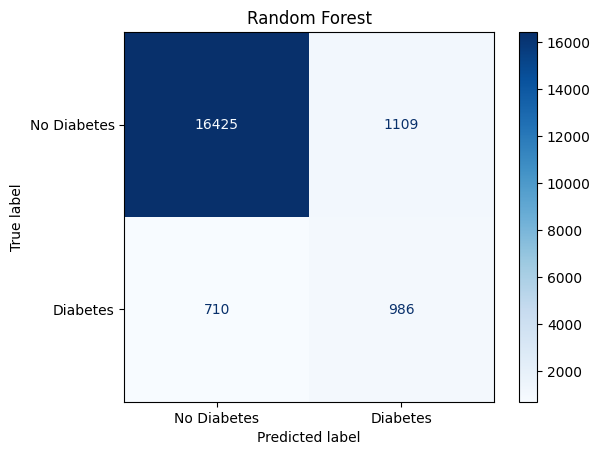

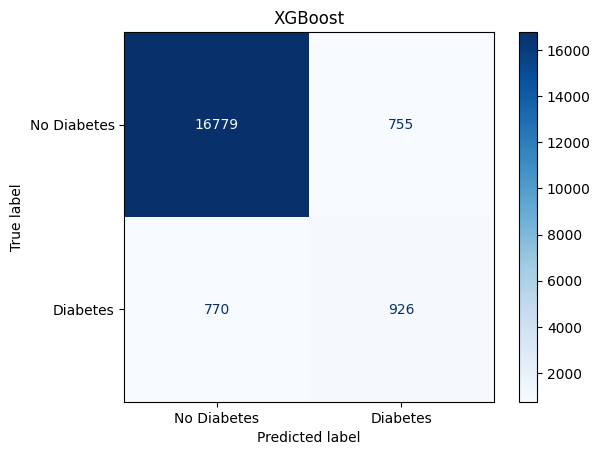

In [63]:
models = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

for name, predictions in models.items():

    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Diabetes', 'Diabetes']
    )

    disp.plot(cmap='Blues')
    plt.title(name)
    plt.show()

In [47]:
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]
y_prob_xgb = xgb.predict_proba(X_test_scaled)[:, 1]

In [48]:
print("Logistic Regression ROC-AUC:",
      roc_auc_score(y_test, y_prob_lr))

print("Random Forest ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf))

print("XGBoost ROC-AUC:",
      roc_auc_score(y_test, y_prob_xgb))

Logistic Regression ROC-AUC: 0.8999905137135185
Random Forest ROC-AUC: 0.8889484392587125
XGBoost ROC-AUC: 0.9187548995106004


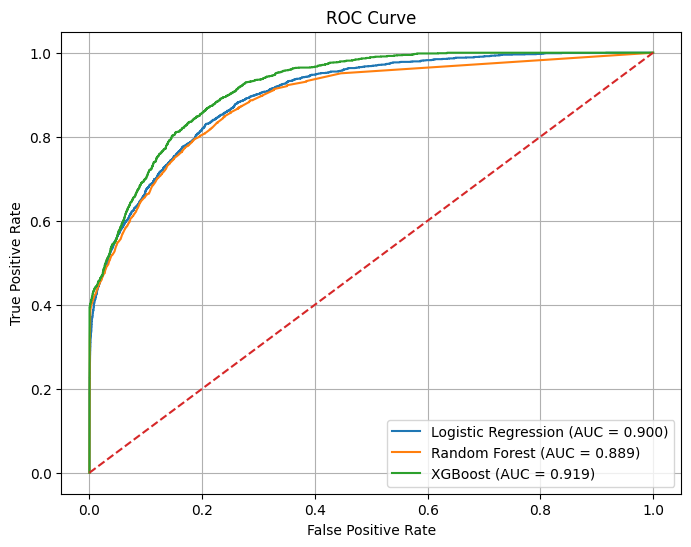

In [49]:
# Calculate ROC curve values
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

# Calculate AUC
auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_xgb = roc_auc_score(y_test, y_prob_xgb)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.show()

In [55]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.810556,0.291050,0.799528,0.426751,0.899991
1,Random Forest,0.905408,0.470644,0.581368,0.520179,0.888948
2,XGBoost,0.920697,0.550863,0.545991,0.548416,0.918755
